# Breathhold correction: visual inspection and hyperparameters

Runs `mrisr-breathhold`'s optimisation (`preprocess/breathhold/optimise.py`) on one subject **without writing anything to disk**,
and shows the slices before and after correction, so you can pick values for:

| hyperparameter | CLI flag | default | what it controls |
|---|---|---|---|
| `ROUNDS` | `--rounds` | 3 | maximum short-axis searches, each followed by a long-axis refinement |
| `SEARCH_RADIUS` | `--search_radius` | 15 | largest short-axis shift searched (voxels, in x and y) |
| `LAX_STEPS` | `--lax_steps` | 300 | maximum Adam steps per long-axis refinement |
| `LAX_PATIENCE` | `--lax_patience` | 30 | stop a refinement after this many steps with no new best loss |
| `LR_LAX` | `--lr_lax` | 1e-2 | step size of the long-axis rotations (radians) and translations (voxels) |
| `SEG_WEIGHT` | `--seg_weight` | 1.0 | weight of the heart-overlap term, where both planes are segmented (0 to ignore segmentations) |
| `METRIC` | `--metric` | ncc | `ncc` (ignores gain/contrast differences between slices) or `l2` |
| `LINE_MM` | `--line_mm` | 120 | length of each intersection compared, centred between the two images (`None` / `0`: half the largest image) |

**How it works.** Each short-axis slice's whole-voxel shift is found by exhaustive search within `SEARCH_RADIUS`, long-axis planes fixed
(exact, since short-axis slices are only paired with long-axis planes); then the long-axis rigid transforms by gradient descent, shifts
fixed; repeated until a search changes nothing. Where both planes of a pair are segmented, the heart-overlap term guides each stage first
and intensities alone finish it. A saved shift at `±SEARCH_RADIUS` means the search hit its edge: increase the radius.

Sections:
1. Set-up and subject choice
2. Hyperparameters and an optimisation run, with its loss curve
3. Before and after: short-axis slices resampled onto each long-axis plane
4. Before and after: the intensity profiles along slice intersections, which are what the loss compares
5. Size of the corrections, and the loss of each pair
6. A small sweep over subjects and settings
7. (Optional) saving a correction

Each figure can also show the correction saved on disk (`*_affine_correction.npy`) from an earlier `slurm/breathhold.sh` run, next to this run.

Run this on a compute node: it uses the GPU if there is one, and otherwise the CPU (slower, but fine for a handful of subjects).
It needs `matplotlib` and a Jupyter kernel: `uv sync --group notebook`.

## 1. Set-up

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.ndimage import map_coordinates

from mrisr_vae.preprocess.breathhold import optimise
from mrisr_vae.preprocess.breathhold.files import find_subjects
from mrisr_vae.preprocess.breathhold.geometry import get_image_plane_from_array, plane_intersection
from mrisr_vae.preprocess.breathhold.loss import NO_OVERLAP_LOSS
from mrisr_vae.preprocess.breathhold.subject import NoValidLongAxisPlanes, SubjectData

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
# DATA_DIR = REPO_ROOT.parent / "scratch/data/kaggle_niftis/train"  # For CSF
DATA_DIR = "/Volumes/MyPassport/kaggle_data_dcm/niftis//train"  # For local
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

subjects = find_subjects(DATA_DIR)
subjects_by_name = {s.path.name: s for s in subjects}
print(f"{len(subjects)} subjects in {DATA_DIR}, running on {DEVICE}")
print("first few:", " ".join(list(subjects_by_name)[:20]))

FileNotFoundError: /Volumes/MyPassport/kaggle_data_dcm/niftis/train is not a directory

Helper functions: correction states, resampling, and plotting. Nothing here needs editing.

In [3]:
def to_np(x):
    return x.detach().cpu().numpy() if torch.is_tensor(x) else np.asarray(x)


def plane_labels(data):
    """A readable label per plane: la_4ch, sa_1[0], sa_1[1], ..."""
    labels, counts = [], {}
    for name in data.names:
        if "sa" in name:
            k = counts.get(name, 0)
            counts[name] = k + 1
            labels.append(f"{name}[{k}]")
        else:
            labels.append(name)
    return labels


def disk_voxel_transformations(data):
    """The corrections saved on disk as (n_planes, 4, 4) voxel transforms, like
    AlignmentResult.voxel_transformations. None if any view has no file."""
    transforms = torch.eye(4, dtype=data.affines.dtype).repeat(len(data.names), 1, 1)
    counts = {}
    for i, name in enumerate(data.names):
        path = data.subject_path / f"{name}_affine_correction.npy"
        if not path.is_file():
            return None
        correction = np.load(path)
        if "sa" in name:
            k = counts.get(name, 0)
            counts[name] = k + 1
            if k >= len(correction):
                return None  # A file from a stack with a different number of slices.
            transforms[i, :2, 3] = torch.as_tensor(correction[k], dtype=transforms.dtype)
        else:
            transforms[i] = torch.as_tensor(correction, dtype=transforms.dtype)
    return transforms.to(data.affines.device)


def correction_states(data, result=None, include_disk=True):
    """name -> corrected affines (n_planes, 4, 4), always starting with 'before'."""
    states = {"before": data.affines}
    if result is not None:
        states["this run"] = data.affines @ result.voxel_transformations
    if include_disk:
        disk = disk_voxel_transformations(data)
        if disk is not None:
            states["on disk"] = data.affines @ disk
    return states


def display_range(data, percentile=99.5):
    images = to_np(data.images_pad)
    return 0.0, float(np.percentile(images[images > 0], percentile))


def reslice_sa_onto(data, affines, target):
    """The short-axis slices resampled onto plane `target`'s pixel grid. Each pixel
    takes the slice whose slab (half the slice spacing either side) contains it;
    NaN where there is none."""
    A = to_np(affines).astype(np.float64)
    images = to_np(data.images_pad[..., 0])
    shapes = to_np(data.shapes)
    H, W = shapes[target][:2]
    ii, jj = np.meshgrid(np.arange(H), np.arange(W), indexing="ij")
    world = A[target] @ np.stack([ii.ravel(), jj.ravel(), np.zeros(H * W), np.ones(H * W)])
    out = np.full(H * W, np.nan)
    nearest = np.full(H * W, np.inf)
    for s in np.where(["sa" in n for n in data.names])[0]:
        uvw = np.linalg.inv(A[s]) @ world
        h, w = shapes[s][:2]
        dist = np.abs(uvw[2])
        ok = (dist <= 0.5) & (dist < nearest)
        ok &= (uvw[0] >= 0) & (uvw[0] <= h - 1) & (uvw[1] >= 0) & (uvw[1] <= w - 1)
        if ok.any():
            out[ok] = map_coordinates(images[s], uvw[:2, ok], order=1)
            nearest[ok] = dist[ok]
    return out.reshape(H, W)


def intersection_in_plane(affines, target, other):
    """Two points, in `target`'s voxel coordinates (i, j), on the line where
    plane `other` cuts plane `target`."""
    planes = get_image_plane_from_array(affines[[int(target), int(other)]])
    line = to_np(plane_intersection(planes[:1], planes[1:])[0]).astype(np.float64)  # (2, 3) in mm
    points = np.c_[line, np.ones(2)]
    vox = np.linalg.inv(to_np(affines[target]).astype(np.float64)) @ points.T
    return vox[:2].T


def show(ax, image, vmin, vmax, title=None):
    """An (x, y) array with x along the horizontal axis."""
    ax.imshow(image.T, cmap="gray", vmin=vmin, vmax=vmax, origin="lower", interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9)


def overlay(la, sa, vmin, vmax):
    """Magenta: long-axis image. Green: resliced short-axis. Grey where they agree."""
    la = np.clip((la - vmin) / (vmax - vmin), 0, 1)
    sa = np.clip((sa - vmin) / (vmax - vmin), 0, 1)
    sa = np.where(np.isnan(sa), la, sa)
    return np.stack([la, sa, la], axis=-1).transpose(1, 0, 2)


def pair_losses(data, affines):
    return to_np(
        optimise.compute_pairwise_loss(
            data.images_pad, data.segs_pad, data.has_seg, affines, data.idx_pairs, data.shapes, data.spacings,
            optimise.LossOptions(SEG_WEIGHT, METRIC, LINE_MM),
        )
    )


def describe_corrections(data, affines_before, affines_after):
    """One line per plane with the correction in mm and degrees."""
    A0 = to_np(affines_before).astype(np.float64)
    A1 = to_np(affines_after).astype(np.float64)
    shapes = to_np(data.shapes)
    rows = []
    for i, label in enumerate(plane_labels(data)):
        centre = np.array([shapes[i][0] / 2, shapes[i][1] / 2, 0, 1])
        shift_mm = np.linalg.norm((A1[i] @ centre - A0[i] @ centre)[:3])
        # Rigid rotation in mm space between the two affines.
        R = A1[i, :3, :3] @ np.linalg.inv(A0[i, :3, :3])
        angle = np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1)))
        rows.append((label, shift_mm, angle))
    return rows

## 2. Hyperparameters and a run

Choose a subject and the settings, then run. Re-run from here to try other settings; nothing is saved.

In [13]:
SUBJECT = next(iter(subjects_by_name))  # e.g. "1", "10", ...
ROUNDS = optimise.ROUNDS  # 3
SEARCH_RADIUS = optimise.SEARCH_RADIUS  # 15
LAX_STEPS = optimise.LAX_STEPS  # 300
LAX_PATIENCE = optimise.LAX_PATIENCE  # 30
LR_LAX = optimise.LR_LAX  # 1e-2
SEG_WEIGHT = optimise.SEG_WEIGHT  # 1.0
METRIC = optimise.METRIC  # "ncc"
LINE_MM = optimise.LINE_MM  # 120.0
SHOW_DISK = True  # also show the correction saved on disk, if there is one

In [14]:
data = SubjectData(subjects_by_name[SUBJECT], device=DEVICE)
labels = plane_labels(data)
sa_idx = [int(i) for i in np.where(["sa" in n for n in data.names])[0]]
la_idx = [int(i) for i in np.where(["sa" not in n for n in data.names])[0]]
print(f"subject {SUBJECT}: long-axis {[data.names[i] for i in la_idx]}, "
      f"{len(sa_idx)} short-axis slices from {sorted({data.names[i] for i in sa_idx})}, {len(data.idx_pairs)} pairs")

start = time.time()
result = optimise.optimize_affines(
    data, rounds=ROUNDS, search_radius=SEARCH_RADIUS, lax_steps=LAX_STEPS, lax_patience=LAX_PATIENCE,
    lr_lax=LR_LAX, seg_weight=SEG_WEIGHT, metric=METRIC, line_mm=LINE_MM, save=False,
)
sa_shifts = to_np(result.voxel_transformations)[sa_idx, :2, 3]
at_edge = int((np.abs(sa_shifts) >= SEARCH_RADIUS).any(axis=1).sum())
print(f"{result.rounds} rounds in {time.time() - start:.1f} s; segmented planes: {int(data.has_seg.sum())}/{len(data.names)}"
      + (f" ({at_edge} slices at the search edge: increase SEARCH_RADIUS)" if at_edge else ""))

states = correction_states(data, result, include_disk=SHOW_DISK)
vmin, vmax = display_range(data)
print("states shown:", list(states))

subject 1: long-axis ['la_4ch', 'la_2ch'], 11 short-axis slices from ['sa_1'], 23 pairs
1: loss 0.1603 -> 0.07098 in 3 rounds
3 rounds in 106.4 s; segmented planes: 0/13
states shown: ['before', 'this run']


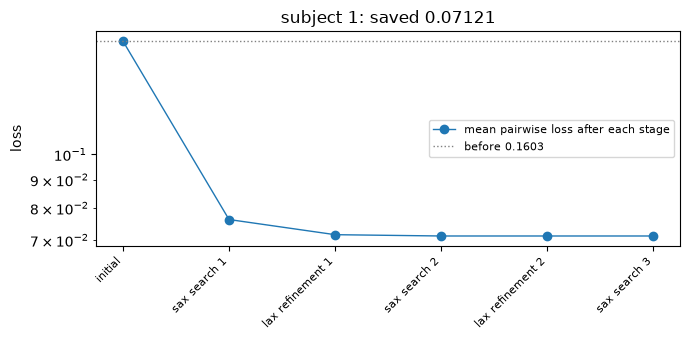

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(result.losses, "o-", lw=1, label="mean pairwise loss after each stage")
ax.axhline(result.initial_loss, color="grey", ls=":", lw=1, label=f"before {result.initial_loss:.4g}")
if "on disk" in states:
    disk_loss = pair_losses(data, states["on disk"]).mean()
    ax.axhline(disk_loss, color="C3", ls=":", lw=1, label=f"on disk {disk_loss:.4g}")
ax.set_xticks(range(len(result.stages)))
ax.set_xticklabels(result.stages, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("loss")
ax.set_yscale("log")
ax.set_title(f"subject {SUBJECT}: saved {result.best_loss:.4g}")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 3. Short-axis slices resampled onto each long-axis plane

For every long-axis view and every correction state (rows): the long-axis image with the short-axis intersection lines,
the short-axis stack resampled onto the same plane, and the two overlaid (magenta = long axis, green = short axis, grey = agreement).
Breathhold misalignment shows up as a staircase of shifted bands in the resampled stack. After a good correction the bands line up
with each other and with the long-axis image.

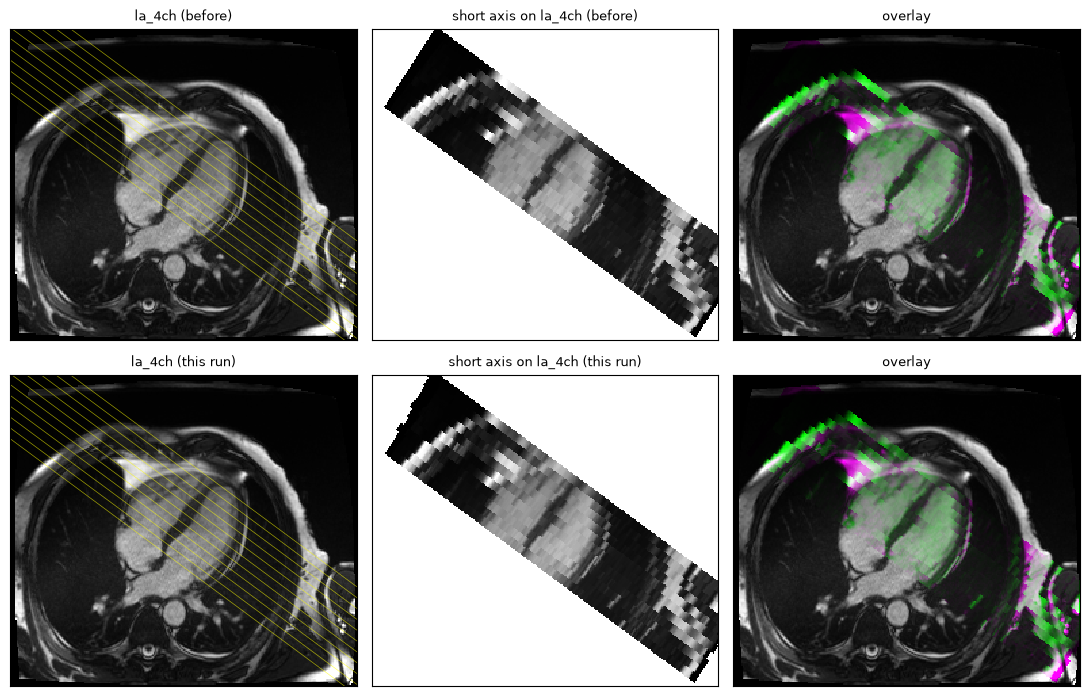

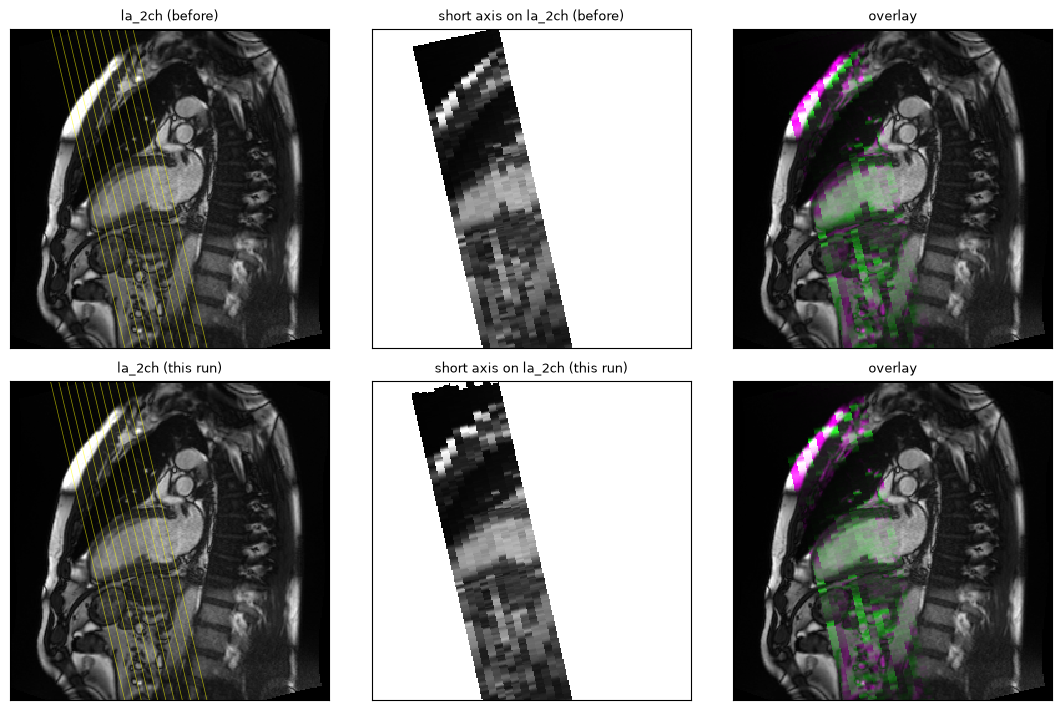

In [12]:
SHOW_LINES = True

for target in la_idx:
    fig, axes = plt.subplots(len(states), 3, figsize=(11, 3.6 * len(states)), squeeze=False)
    for row, (state, affines) in zip(axes, states.items()):
        h, w = (int(n) for n in data.shapes[target][:2])
        la = to_np(data.images_pad[target, :h, :w, 0])
        sa = reslice_sa_onto(data, affines, target)
        show(row[0], la, vmin, vmax, f"{data.names[target]} ({state})")
        if SHOW_LINES:
            for s in sa_idx:
                p0, p1 = intersection_in_plane(affines, target, s)
                row[0].axline(p0, p1, color="yellow", lw=0.5, alpha=0.6)
            row[0].set_xlim(-0.5, la.shape[0] - 0.5)
            row[0].set_ylim(-0.5, la.shape[1] - 0.5)
        show(row[1], sa, vmin, vmax, f"short axis on {data.names[target]} ({state})")
        row[2].imshow(overlay(la, sa, vmin, vmax), origin="lower", interpolation="nearest")
        row[2].set_xticks([])
        row[2].set_yticks([])
        row[2].set_title("overlay", fontsize=9)
    fig.tight_layout()
    plt.show()

## 4. Intersection profiles: what the loss compares

For one long-axis view: each row is one short-axis slice, and the columns are points along that slice's intersection with the
long-axis plane. The left panel of each state is the long-axis image sampled along the line, the middle panel the short-axis slice
sampled along the same line, and the right panel their difference. Points outside the loss mask (the union of the hearts of the
segmented planes, where there is a segmentation, and the image bounds) are blank. When the two are aligned the left and middle panels show the same vertical bands.

In [ ]:
LA_VIEW = data.names[la_idx[0]]  # one of the long-axis views listed above

target = data.names.index(LA_VIEW)
pairs = [k for k, (a, b) in enumerate(to_np(data.idx_pairs)) if a == target and "sa" in data.names[b]]
pair_slices = [labels[to_np(data.idx_pairs)[k][1]] for k in pairs]

fig, axes = plt.subplots(len(states), 3, figsize=(12, 0.25 * len(pairs) * len(states) + 1.5 * len(states)), squeeze=False)
for row, (state, affines) in zip(axes, states.items()):
    im1, im2, _, _, mask, _ = optimise.sample_intersections(
        data.images_pad, data.segs_pad, data.has_seg, affines, data.idx_pairs[pairs], data.shapes, data.spacings, LINE_MM
    )
    im1, im2, mask = (to_np(x[..., 0]) for x in (im1, im2, mask))
    im1 = np.where(mask, im1, np.nan)
    im2 = np.where(mask, im2, np.nan)
    diff = im1 - im2
    lim = np.nanmax(np.abs(diff)) if np.isfinite(diff).any() else 1.0
    for ax, values, title, kwargs in [
        (row[0], im1, f"{LA_VIEW} along line ({state})", dict(cmap="gray", vmin=vmin, vmax=vmax)),
        (row[1], im2, f"short axis along line ({state})", dict(cmap="gray", vmin=vmin, vmax=vmax)),
        (row[2], diff, f"difference, loss {np.nanmean(diff**2):.4g}", dict(cmap="RdBu_r", vmin=-lim, vmax=lim)),
    ]:
        ax.imshow(values, aspect="auto", interpolation="nearest", **kwargs)
        ax.set_title(title, fontsize=9)
        ax.set_yticks(range(len(pairs)))
        ax.set_yticklabels(pair_slices, fontsize=6)
        ax.set_xlabel("point along intersection")
fig.tight_layout()
plt.show()

## 5. Size of the corrections, and the loss of each pair

The short-axis shifts are whole voxels; the long-axis corrections are given as the shift of the image centre (mm) and the rotation (degrees).
Shifts at `±SEARCH_RADIUS` mean the search hit its edge. Shifts of many voxels, or long-axis rotations of tens of degrees, are
suspicious.

In [ ]:
corrected = {k: v for k, v in states.items() if k != "before"}
spacing = to_np(data.spacings)

fig, axes = plt.subplots(1, len(corrected), figsize=(6 * len(corrected), 3), squeeze=False)
for ax, (state, affines) in zip(axes[0], corrected.items()):
    shifts = to_np(torch.linalg.solve(data.affines, affines))[sa_idx, :2, 3]
    x = np.arange(len(sa_idx))
    ax.bar(x - 0.2, shifts[:, 0], 0.4, label="x")
    ax.bar(x + 0.2, shifts[:, 1], 0.4, label="y")
    ax.set_xticks(x)
    ax.set_xticklabels([labels[i] for i in sa_idx], rotation=90, fontsize=6)
    ax.set_ylabel("shift (voxels)")
    moved = np.any(np.round(shifts) != 0, axis=1).mean()
    ax.set_title(f"short-axis shifts ({state}): {moved:.0%} of slices moved, "
                 f"pixel {spacing[sa_idx[0], 0]:.2f} mm", fontsize=9)
    ax.axhline(0, color="k", lw=0.5)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for state, affines in corrected.items():
    print(f"long-axis corrections ({state}):")
    for label, shift_mm, angle in describe_corrections(data, data.affines, affines):
        if "sa" not in label:
            print(f"  {label:8s} centre moved {shift_mm:6.2f} mm, rotated {angle:5.2f} deg")

In [ ]:
pair_names = [f"{labels[a]}–{labels[b]}" for a, b in to_np(data.idx_pairs)]
losses = {state: pair_losses(data, affines) for state, affines in states.items()}

fig, ax = plt.subplots(figsize=(max(8, 0.15 * len(pair_names)), 3.5))
width = 0.8 / len(losses)
for k, (state, values) in enumerate(losses.items()):
    shown = np.where(values >= NO_OVERLAP_LOSS, np.nan, values)
    ax.bar(np.arange(len(values)) + (k - (len(losses) - 1) / 2) * width, shown, width, label=state)
ax.set_xticks(range(len(pair_names)))
ax.set_xticklabels(pair_names, rotation=90, fontsize=5)
ax.set_ylabel("pair loss")
ax.legend(fontsize=8)
ax.set_title("loss of each pair (pairs with no overlap left out)", fontsize=9)
fig.tight_layout()
plt.show()

for state, values in losses.items():
    print(f"{state:9s} mean {values.mean():.4g}, pairs with no overlap: {(values >= NO_OVERLAP_LOSS).sum()}")

## 6. Sweep over subjects and settings

Runs every setting in `GRID` on every subject in `SWEEP_SUBJECTS` (nothing is saved) and tabulates the result. Compare the
fraction of the loss removed, the step the best loss was reached at, whether the run hit `max_epochs`, and the size of the corrections.
Then look at the subjects you are unsure about in sections 3 and 4 by setting `SUBJECT`, the hyperparameters, and re-running from section 2.

In [ ]:
SWEEP_SUBJECTS = list(subjects_by_name)[:5]
GRID = [
    dict(),  # the defaults
    dict(seg_weight=0.0),  # intensities only
    dict(search_radius=25),
    dict(lr_lax=3e-2),
]

rows, curves = [], {}
for name in SWEEP_SUBJECTS:
    try:
        subject_data = SubjectData(subjects_by_name[name], device=DEVICE)
    except NoValidLongAxisPlanes as error:
        print(f"{error}, skipping")
        continue
    sa = np.array(["sa" in n for n in subject_data.names])
    for g, config in enumerate(GRID):
        start = time.time()
        r = optimise.optimize_affines(subject_data, save=False, **config)
        shifts = to_np(r.voxel_transformations)[sa, :2, 3]
        la_rows = describe_corrections(
            subject_data, subject_data.affines, subject_data.affines @ r.voxel_transformations
        )
        la_rows = [row for row, is_sa in zip(la_rows, sa) if not is_sa]
        rows.append(dict(
            subject=name, config=g, rounds=r.rounds,
            at_edge=int((np.abs(shifts) >= config.get("search_radius", optimise.SEARCH_RADIUS)).any(axis=1).sum()),
            before=r.initial_loss, after=r.best_loss, reduction=1 - r.best_loss / r.initial_loss,
            sa_moved=float(np.any(shifts != 0, axis=1).mean()), sa_max_shift=float(np.abs(shifts).max()),
            la_max_mm=float(max(row[1] for row in la_rows)), la_max_deg=float(max(row[2] for row in la_rows)),
            seconds=time.time() - start,
        ))
        curves[name, g] = r.losses

for g, config in enumerate(GRID):
    print(f"config {g}: {config}")
header = ["subject", "config", "rounds", "at_edge", "before", "after", "reduction",
          "sa_moved", "sa_max_shift", "la_max_mm", "la_max_deg", "seconds"]
print()
print("  ".join(f"{h:>12s}" for h in header))
for row in rows:
    print("  ".join(f"{row[h]:>12.4g}" if isinstance(row[h], float) else f"{str(row[h]):>12s}" for h in header))
print()
for g in range(len(GRID)):
    sub = [row for row in rows if row["config"] == g]
    if sub:
        print(f"config {g}: mean reduction {np.mean([r['reduction'] for r in sub]):.1%}, "
              f"mean rounds {np.mean([r['rounds'] for r in sub]):.1f}, slices at the search edge {sum(r['at_edge'] for r in sub)}")

In [ ]:
names = sorted({name for name, _ in curves}, key=SWEEP_SUBJECTS.index)
fig, axes = plt.subplots(1, len(names), figsize=(4 * len(names), 3), squeeze=False, sharey=False)
for ax, name in zip(axes[0], names):
    for g in range(len(GRID)):
        if (name, g) in curves:
            ax.plot(curves[name, g], "o-", lw=1, label=f"config {g}")
    ax.set_title(f"subject {name}", fontsize=9)
    ax.set_xlabel("stage")
axes[0][0].set_ylabel("loss")
axes[0][0].set_yscale("log")
axes[0][0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## 7. Saving (optional)

Writes the correction from section 2 for `SUBJECT`, overwriting its `*_affine_correction.npy` files. Normally you would instead run
`slurm/breathhold.sh` with the chosen options, then rerun `slurm/register.sh`:
long-axis corrections only reach the model through `registration_params.pickle`.

In [ ]:
SAVE = False
if SAVE:
    data.save_transformations(result.transformations)
    print(f"saved the correction of subject {SUBJECT}; rerun mrisr-register for it to take effect")